
=== FMNIST ROUND-1 ATTACKS ===

Class: T-shirt
Class: Trouser
Class: Pullover
Class: Dress
Class: Coat
Class: Sandal
Class: Shirt
Class: Sneaker
Class: Bag
Class: AnkleBoot


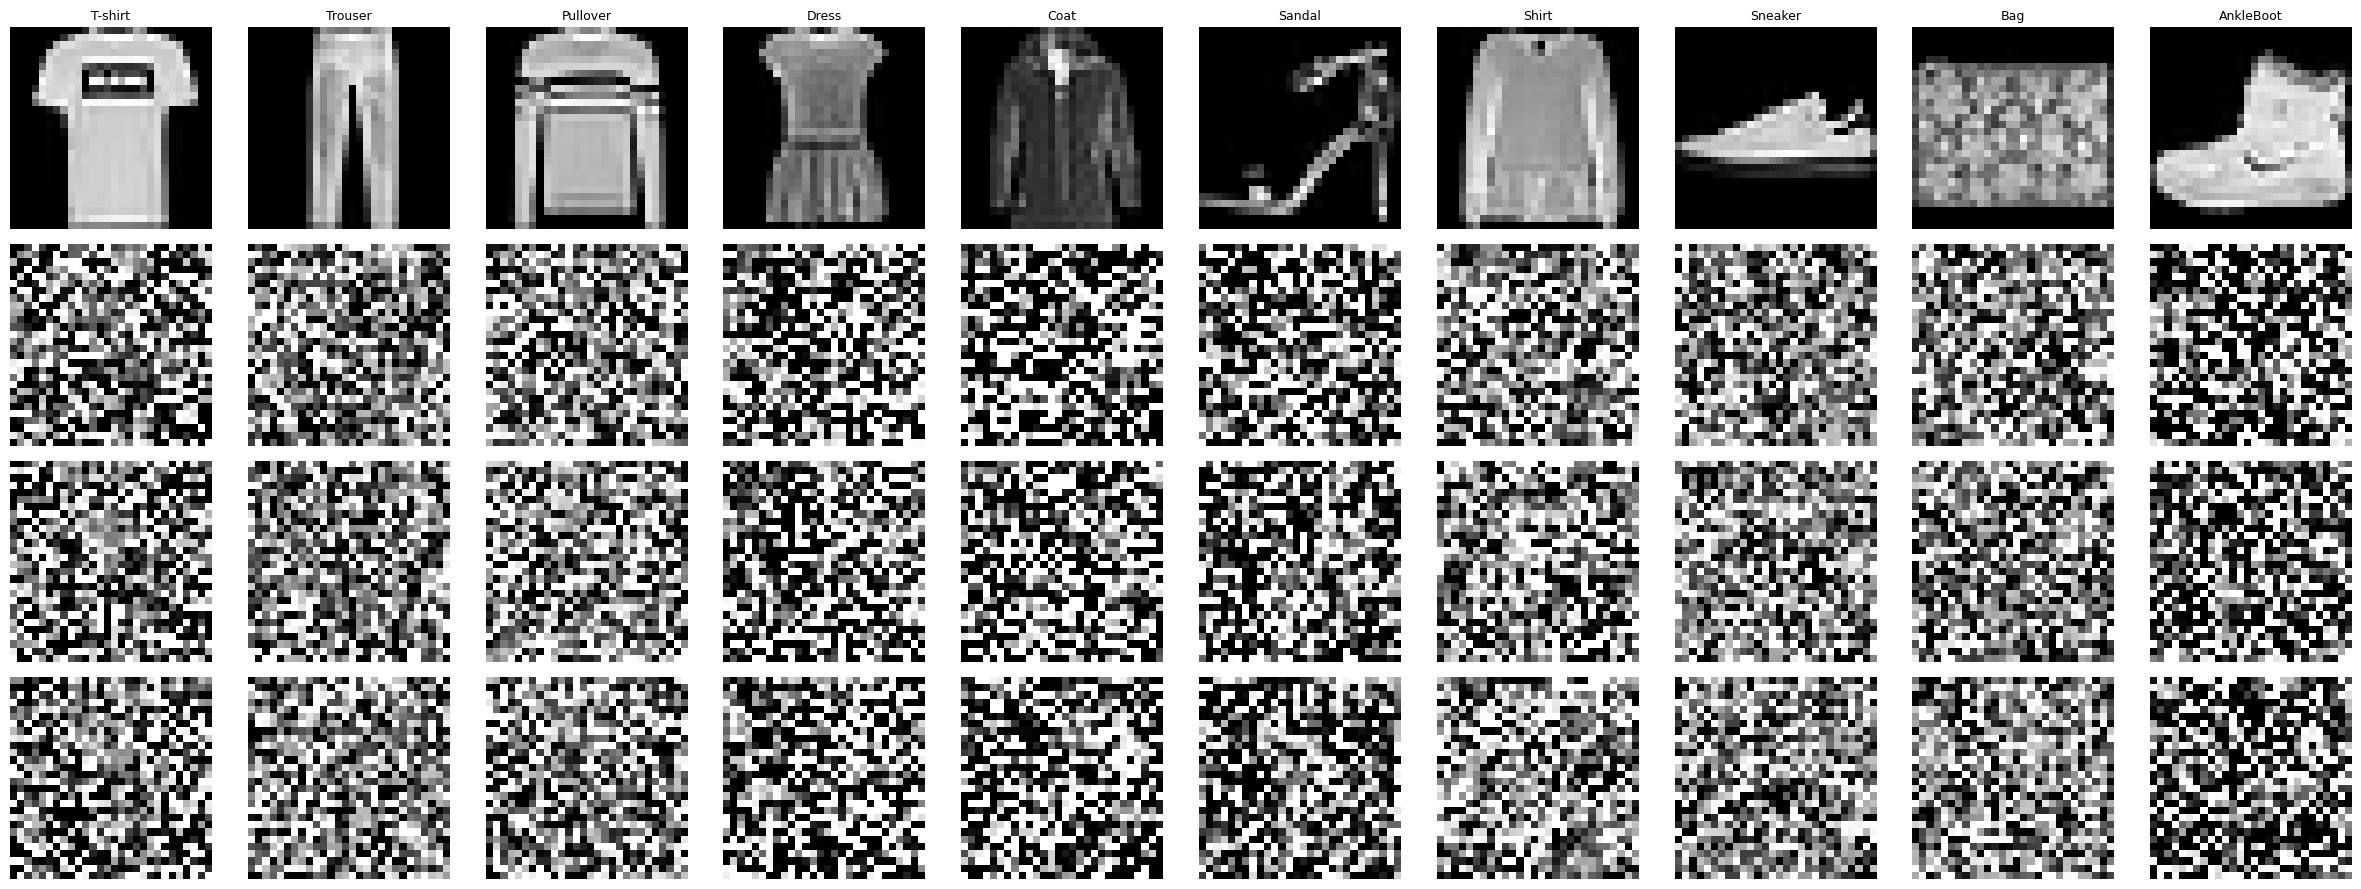

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Saved: fmnist_fpman1_all_attacks.png


In [1]:
# ============================================================
# FMNIST ROUND-1 + MASKING + NOISE + ALL ATTACKS
# Dataset: Fashion-MNIST
# Model: LeNet++ CNN
# Attacks: DLG + iDLG + GradInv
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import random
import copy
import matplotlib.pyplot as plt
from google.colab import files

# ============================================================
# CONFIG
# ============================================================

NUM_CLIENTS = 100
CLIENT_FRAC = 0.3
LOCAL_EPOCHS = 3
BATCH_SIZE = 128

LR = 0.01
MU = 0.01

MASK_SCALE = 0.001
ADAPTIVE_NOISE_FACTOR = 0.1

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
ALPHA = 0.1

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# ============================================================
# DATASET
# ============================================================

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

targets = np.array(train_dataset.targets)

# ============================================================
# CLASS NAMES
# ============================================================

CLASS_NAMES = {
    0: "T-shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "AnkleBoot"
}

# ============================================================
# DIRICHLET NON-IID SPLIT
# ============================================================

def dirichlet_partition(dataset, clients, alpha=0.1):

    num_classes = 10

    labels = np.array(dataset.targets)

    idxs = np.arange(len(labels))

    client_dict = {
        i: []
        for i in clients
    }

    class_indices = [
        idxs[labels == i]
        for i in range(num_classes)
    ]

    for c_idx in class_indices:

        np.random.shuffle(c_idx)

        proportions = np.random.dirichlet(
            alpha * np.ones(len(clients))
        )

        proportions = (
            np.cumsum(proportions) * len(c_idx)
        ).astype(int)

        proportions = np.concatenate(([0], proportions))

        for i, client in enumerate(clients):

            client_dict[client] += list(
                c_idx[proportions[i]:proportions[i+1]]
            )

    for client in clients:

        np.random.shuffle(client_dict[client])

    return client_dict

client_data = dirichlet_partition(
    train_dataset,
    list(range(NUM_CLIENTS)),
    alpha=ALPHA
)

# ============================================================
# MODEL
# ============================================================

class FMNIST_CNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.conv1 = nn.Conv2d(
            1, 32, 3, padding=1
        )

        self.conv2 = nn.Conv2d(
            32, 64, 3, padding=1
        )

        self.pool = nn.MaxPool2d(2)

        self.fc1 = nn.Linear(
            64 * 7 * 7,
            256
        )

        self.fc2 = nn.Linear(
            256,
            10
        )

    def forward(self, x):

        x = self.pool(
            F.relu(self.conv1(x))
        )

        x = self.pool(
            F.relu(self.conv2(x))
        )

        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))

        return self.fc2(x)

# ============================================================
# FEDPROX LOSS
# ============================================================

def fedprox_loss(model, global_model, mu):

    prox = 0.0

    for w, w0 in zip(
        model.parameters(),
        global_model.parameters()
    ):

        prox += torch.sum(
            (w - w0.detach()) ** 2
        )

    return mu / 2 * prox

# ============================================================
# VECTOR HELPERS
# ============================================================

def model_to_vector(model):

    return torch.cat([
        p.data.view(-1)
        for p in model.parameters()
    ])

def vector_to_model(model, vec):

    pointer = 0

    for p in model.parameters():

        num = p.numel()

        p.data = (
            vec[pointer:pointer + num]
            .view_as(p)
            .clone()
        )

        pointer += num

# ============================================================
# IMAGE NORMALIZATION
# ============================================================

def norm_img(x):

    x = x - x.min()

    x = x / (x.max() + 1e-8)

    return x

# ============================================================
# GLOBAL MODEL
# ============================================================

global_model = FMNIST_CNN().to(DEVICE)

global_vec = model_to_vector(global_model)

# ============================================================
# CLIENT SELECTION
# ============================================================

selected_clients = random.sample(
    range(NUM_CLIENTS),
    int(NUM_CLIENTS * CLIENT_FRAC)
)

# ============================================================
# MASKING
# ============================================================

masks = {
    cid: torch.zeros_like(global_vec)
    for cid in selected_clients
}

sorted_ids = sorted(selected_clients)

for i, cid in enumerate(sorted_ids):

    right = sorted_ids[
        (i + 1) % len(sorted_ids)
    ]

    if cid < right:

        m = (
            torch.randn_like(global_vec)
            * MASK_SCALE
        )

        masks[cid] += m
        masks[right] -= m

# ============================================================
# STORE
# ============================================================

updates = []
labels = []

fashion_samples = {}

for img, y in train_dataset:

    y = int(y)

    if y not in fashion_samples:

        fashion_samples[y] = img

    if len(fashion_samples) == 10:

        break

# ============================================================
# ROUND-1 TRAINING
# ============================================================

for cid in selected_clients:

    local_model = copy.deepcopy(global_model)

    local_model.train()

    optimizer = optim.SGD(
        local_model.parameters(),
        lr=LR,
        momentum=0.9,
        weight_decay=5e-4
    )

    loader = DataLoader(
        Subset(train_dataset, client_data[cid]),
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    for _ in range(LOCAL_EPOCHS):

        for x, y in loader:

            x = x.to(DEVICE)
            y = y.to(DEVICE)

            optimizer.zero_grad()

            out = local_model(x)

            loss = F.cross_entropy(out, y)

            loss += fedprox_loss(
                local_model,
                global_model,
                MU
            )

            loss.backward()

            optimizer.step()

    # ========================================================
    # UPDATE
    # ========================================================

    delta = (
        model_to_vector(local_model)
        - global_vec
    )

    # ========================================================
    # ADAPTIVE NOISE
    # ========================================================

    pointer = 0

    for p in local_model.parameters():

        num = p.numel()

        layer_update = (
            delta[pointer:pointer + num]
            .view_as(p)
        )

        layer_norm = torch.norm(layer_update)

        noise = (
            torch.randn_like(layer_update)
            * layer_norm
            * ADAPTIVE_NOISE_FACTOR
        )

        delta[pointer:pointer + num] += (
            noise.view(-1)
        )

        pointer += num

    # ========================================================
    # MASKING
    # ========================================================

    delta += masks[cid]

    updates.append(delta.detach().clone())

    client_labels = targets[client_data[cid]]

    labels.append(
        np.bincount(client_labels).argmax()
    )

# ============================================================
# ATTACK 1: DLG
# ============================================================

def dlg_attack(update, label):

    model = copy.deepcopy(global_model).to(DEVICE)

    vector_to_model(
        model,
        global_vec + update
    )

    x = torch.randn(
        1,
        1,
        28,
        28,
        device=DEVICE,
        requires_grad=True
    )

    optimizer = optim.Adam([x], lr=0.1)

    y = torch.tensor([label]).to(DEVICE)

    for _ in range(200):

        optimizer.zero_grad()

        pred = model(x)

        loss = F.cross_entropy(pred, y)

        loss.backward()

        optimizer.step()

        x.data.clamp_(-1, 1)

    return x.detach()

# ============================================================
# ATTACK 2: iDLG
# ============================================================

def idlg_attack(update):

    best_img = None

    best_loss = 1e9

    for label in range(10):

        model = copy.deepcopy(global_model).to(DEVICE)

        vector_to_model(
            model,
            global_vec + update
        )

        x = torch.randn(
            1,
            1,
            28,
            28,
            device=DEVICE,
            requires_grad=True
        )

        optimizer = optim.Adam([x], lr=0.1)

        y = torch.tensor([label]).to(DEVICE)

        for _ in range(100):

            optimizer.zero_grad()

            pred = model(x)

            loss = F.cross_entropy(pred, y)

            loss.backward()

            optimizer.step()

            x.data.clamp_(-1, 1)

        if loss.item() < best_loss:

            best_loss = loss.item()

            best_img = x.detach()

    return best_img

# ============================================================
# ATTACK 3: GradInv
# ============================================================

def gradinv_attack(update, label):

    model = copy.deepcopy(global_model).to(DEVICE)

    vector_to_model(
        model,
        global_vec + update
    )

    x = torch.randn(
        1,
        1,
        28,
        28,
        device=DEVICE,
        requires_grad=True
    )

    optimizer = optim.Adam([x], lr=0.1)

    y = torch.tensor([label]).to(DEVICE)

    for _ in range(200):

        optimizer.zero_grad()

        pred = model(x)

        loss = F.cross_entropy(pred, y)

        loss.backward()

        optimizer.step()

        x.data.clamp_(-1, 1)

    return x.detach()

# ============================================================
# RUN ATTACKS
# ============================================================

print("\n=== FMNIST ROUND-1 ATTACKS ===\n")

orig = []
dlg = []
idlg = []
gi = []

for i in range(10):

    update = updates[i]

    label = labels[i]

    print("Class:", CLASS_NAMES[i])

    orig.append(
        fashion_samples[i]
        .squeeze()
        .cpu()
        .numpy()
    )

    dlg.append(
        dlg_attack(update, label)
        .squeeze()
        .cpu()
        .numpy()
    )

    idlg.append(
        idlg_attack(update)
        .squeeze()
        .cpu()
        .numpy()
    )

    gi.append(
        gradinv_attack(update, label)
        .squeeze()
        .cpu()
        .numpy()
    )

# ============================================================
# VISUALIZATION
# ============================================================

fig, axes = plt.subplots(
    4,
    10,
    figsize=(24, 9)
)

for i in range(10):

    axes[0, i].imshow(
        norm_img(orig[i]),
        cmap="gray"
    )

    axes[1, i].imshow(
        norm_img(dlg[i]),
        cmap="gray"
    )

    axes[2, i].imshow(
        norm_img(idlg[i]),
        cmap="gray"
    )

    axes[3, i].imshow(
        norm_img(gi[i]),
        cmap="gray"
    )

    axes[0, i].set_title(
        CLASS_NAMES[i],
        fontsize=9
    )

    for j in range(4):

        axes[j, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("DLG")
axes[2, 0].set_ylabel("iDLG")
axes[3, 0].set_ylabel("GradInv")

plt.tight_layout()

# ============================================================
# SAVE + DOWNLOAD
# ============================================================

SAVE_PATH = "fmnist_fpman1_all_attacks.png"

plt.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

files.download(SAVE_PATH)

print("\nSaved:", SAVE_PATH)

In [2]:
# =====================================================
# SAVE SEPARATE IMAGE ROWS FOR FMNIST
# =====================================================

from google.colab import files

# -------------------------
# helper function
# -------------------------
def save_row(images, filename):

    fig, axes = plt.subplots(1, 10, figsize=(20, 2))

    for i in range(10):

        img = images[i]

        if torch.is_tensor(img):

            img = img.detach().cpu().numpy()

        img = np.squeeze(img)

        axes[i].imshow(img, cmap="gray")

        axes[i].axis("off")

    plt.subplots_adjust(
        left=0,
        right=1,
        top=1,
        bottom=0,
        wspace=0.12,
        hspace=0
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0
    )

    plt.close()

# =====================================================
# BUILD ROW LISTS
# =====================================================

original_results = orig
dlg_results = dlg
idlg_results = idlg
gi_results = gi

# =====================================================
# SAVE 4 ROW IMAGES
# =====================================================

save_row(
    original_results,
    "fmnist_fpman1_original_row.png"
)

save_row(
    dlg_results,
    "fmnist_fpman1_dlg_row.png"
)

save_row(
    idlg_results,
    "fmnist_fpman1_idlg_row.png"
)

save_row(
    gi_results,
    "fmnist_fpman1_gradinv_row.png"
)

print("\nALL ROW IMAGES SAVED\n")

# =====================================================
# DOWNLOAD
# =====================================================

files.download("fmnist_fpman1_original_row.png")
files.download("fmnist_fpman1_dlg_row.png")
files.download("fmnist_fpman1_idlg_row.png")
files.download("fmnist_fpman1_gradinv_row.png")


ALL ROW IMAGES SAVED



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>